# 05 — Customer analytics
Calculate customer purchase frequency and monetary value from order and customer tables.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ecommerce_analytics.config import ConfigManager
from ecommerce_analytics.db_engine import DatabaseEngine
from ecommerce_analytics.customer_analytics import CustomerAnalytics

# Initialize customer engine
db = DatabaseEngine()
analytics = CustomerAnalytics(db_engine=db)

DATABASE_URL not found in .env. Falling back to local SQLite: C:\Users\nazmu\Documents\data_analysis\ecommerce-analytics\data\processed\ecommerce_analytics.db


In [2]:
# Calculate RFM scores
rfm_df = analytics.get_rfm_scores()

# Render segment summary table
segment_summary = analytics.get_segment_summary(rfm_df)
display(segment_summary)

,customer_segment,customer_count,avg_recency_days,avg_frequency,avg_monetary_spend,total_segment_revenue,customer_percentage
7,Promising / Recent Buyers,21191,91.232080,1.000000,211.214391,4475844.17,22.70
3,Hibernating High Value,13646,394.816869,1.000000,278.146613,3795588.68,14.62
4,Lost / Inactive,32958,340.689302,1.000000,100.285191,3305199.34,35.30
6,New / Casual Buyers,22762,133.877295,1.000000,40.262594,916457.17,24.38
2,Champions (VIP),937,89.354322,2.189968,327.088378,306481.81,1.00
5,Loyal Customers,876,177.608447,2.070776,203.619463,178370.65,0.94
0,At Risk (Need Attention),553,317.486438,2.081374,250.646148,138607.32,0.59
1,Cant Lose Them (High Spend Churned),435,464.747126,2.078161,241.262000,104948.97,0.47


In [3]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=segment_summary,
    x="total_segment_revenue",
    y="customer_segment",
    palette="viridis"
)
plt.title("Total Revenue Contribution by Customer Segment (BRL)")
plt.xlabel("Total Revenue (BRL)")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

C:\Users\nazmu\AppData\Local\Temp\ipykernel_11824\1985157368.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
c:\Users\nazmu\Documents\data_analysis\ecommerce-analytics\.venv\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\nazmu\Documents\data_analysis\ecommerce-analytics\.venv\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\nazmu\Documents\data_analysi

<Figure size 1000x500 with 1 Axes>

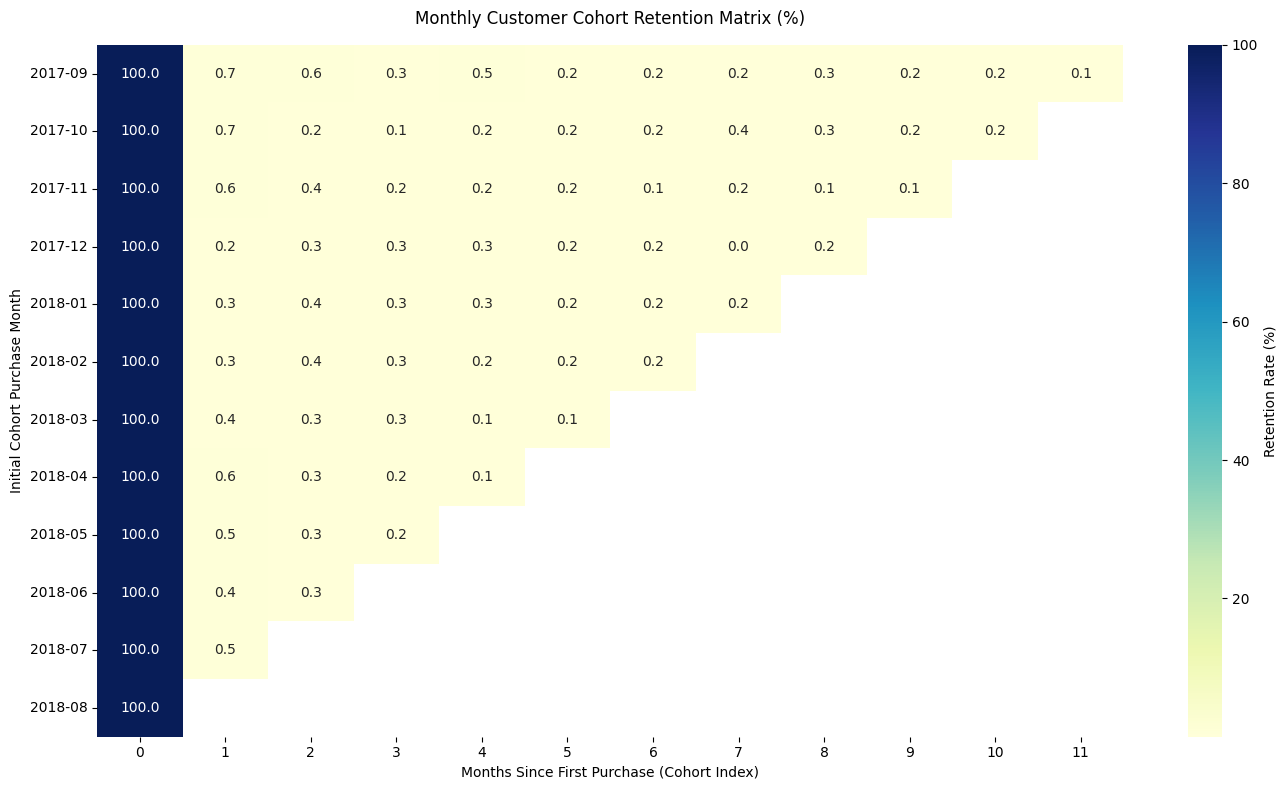

In [4]:
# Compute Retention Matrix
retention_df = analytics.calculate_cohort_retention()

# Render Cohort Heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(
    data=retention_df.iloc[-12:, :12],  # Last 12 cohorts over 12 months
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={'label': 'Retention Rate (%)'}
)
plt.title("Monthly Customer Cohort Retention Matrix (%)", pad=15)
plt.xlabel("Months Since First Purchase (Cohort Index)")
plt.ylabel("Initial Cohort Purchase Month")
plt.tight_layout()
plt.show()